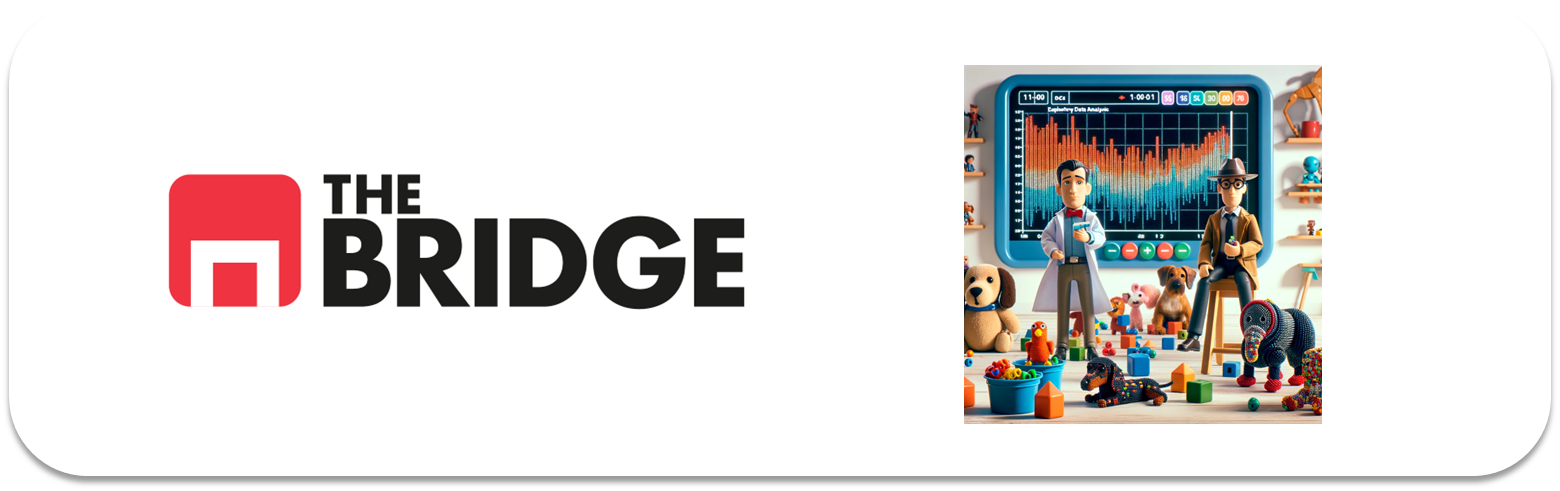

## PRACTICA OBLIGATORIA: ANÁLISIS MULTIVARIANTE

### Ejercicio 0


Importa los paquetes y módulos que necesites a lo largo del notebook

In [2]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns


In [3]:

from bootcampviztools import plot_combined_graphs, pinta_distribucion_categoricas, plot_categorical_relationship_fin, \
      plot_grouped_boxplots, plot_grouped_histograms, grafico_dispersion_con_correlacion, \
      plot_categorical_numerical_relationship, bubble_plot
from scipy.stats import pearsonr, spearmanr, chi2_contingency, mannwhitneyu, f_oneway

## #1 TITANIC

### #1.1

Carga en un dataframe el dataset del titanic, que está en la ruta "./data/titanic.csv".

In [4]:
import os
ruta_datos = "./data/" if os.path.exists("./data/titanic.csv") else "../data/"
df_titanic = pd.read_csv(ruta_datos + "titanic.csv")
df_titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
df_titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


### #1.2

Deshazte de las columnas "deck", "survived", "pclass" y "embarked" porque no las emplearemos, la primera por su cantidad de nulos y el resto porque son variantes de otras que ya existen y cuyos valores resultan más expresivos a la hora de hacer un análisis. 

In [6]:
df_titanic = df_titanic.drop(columns=["deck", "survived", "pclass", "embarked"])
df_titanic.head()

,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone
0,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False
1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False
2,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True
3,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False
4,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True


### #1.3

Suma las columnas "parch" y "sibsp" para tener el número de parientes de cada pasajero, guarda el resultado en otra columna "family_members", luego deshazte de "parch" y "sibsp"

In [7]:
df_titanic["family_members"] = df_titanic["parch"] + df_titanic["sibsp"]
df_titanic = df_titanic.drop(columns=["parch", "sibsp"])
df_titanic["family_members"].value_counts()

family_members
0     537
1     161
2     102
3      29
5      22
4      15
6      12
10      7
7       6
Name: count, dtype: int64

### #1.4

Imputa la moda a los valores nulos de "embark_town"

In [65]:
print("Nulos antes:", df_titanic["embark_town"].isnull().sum(), " Moda:", df_titanic["embark_town"].mode()[0])
df_titanic["embark_town"] = df_titanic["embark_town"].fillna(df_titanic["embark_town"].mode()[0])
print("Nulos después:", df_titanic["embark_town"].isnull().sum())

Nulos antes: 0  Moda: Southampton
Nulos después: 0


### #1.5

Imputa la media a los valores faltantes de "age", si quieres puedes hacer algo más preciso (por ejemplo considerando además la columna "who")

In [9]:
print(df_titanic.groupby("who")["age"].mean().round(2))
media_por_grupo = df_titanic.groupby("who")["age"].transform("mean")
df_titanic["age"] = df_titanic["age"].fillna(media_por_grupo)
df_titanic.isnull().sum()

who
child     6.37
man      33.17
woman    32.00
Name: age, dtype: float64


sex               0
age               0
fare              0
class             0
who               0
adult_male        0
embark_town       0
alive             0
alone             0
family_members    0
dtype: int64

### 1.6

Realiza los análisis bivariantes o multivariantes que necesites, así como los test de hipótesis necesarios para contestar a las siguientes preguntas. Nota: utiliza la variable "alive" para saber si un pasajero sobrevivió o no:

*Tabla de la teoría de Análisis Multivariante:*

| Variables que se cruzan | Análisis visual | Test | H0 ("aquí no ha pasado nada") |
|---|---|---|---|
| Categórica – categórica | `plot_categorical_relationship_fin` (absoluto y relativo) | **Chi-cuadrado** (`chi2_contingency`) | Las variables son independientes |
| Numérica – binaria | Histogramas y boxplots por grupo | **t de Student** si son normales; si no, **U de Mann-Whitney** | Las dos poblaciones tienen la misma distribución |
| Numérica – categórica (> 2 grupos) | Histogramas y boxplots por grupo | **ANOVA** (`f_oneway`) | Todos los grupos tienen la misma media |
| Numérica – numérica | Diagrama de dispersión | **Pearson** (`pearsonr`) | No hay relación lineal |

Regla de decisión con alfa = 0,05: **p-valor <= 0,05 → rechazo H0** (la relación es estadísticamente significativa). **p-valor > 0,05 → no  rechazar H0** (lo que no equivale a aceptarla).

Función para no repetir el test chi-cuadrado:

1. En términos absolutos, ¿sobrevivieron más hombres, mujeres o niños? ¿Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre el sexo y la supervivencia en el Titanic?¿Y entre ser adulto o ser niño?

2. En términos absolutos, ¿de que clase sobrevivieron más pasajeros?¿ Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre la clase en la que se viajaba y la supervivencia?

3. ¿De qué ciudad sobrevivieron más personas?¿Y porcentualmente de que ciudad sobrevivieron más personas? ¿Hay alguna relación estadística significativa entre haber embarcado en una de las tres ciudades y haber sobrevivido o fallecido?

4. ¿Qué relación hay entre el precio del pasaje y la supervivencia/fallecimiento?

5. Existen pasajero que no pagaron el billete, ¿podrías explicar por qué? ¿Qué ocurrió con la persona que más dinero se dejó?

6. Existe alguna relación entre el dinero pagado, la ciudad de embarque y la superviviencia/fallecimiento. No necesitas aplicar ningún test, muestralo numérica o visualmente.

7. Ahondando en la relación entre sobrevivir o fallecer, la clase en la que se viajó y la edad de los pasajeros. ¿Qué agrupación de las dos variables (clase y edad) sobrevivió más en términos absolutos y en términos relativos?

8. Finalmente, muestra las posibles relaciones entre edad, coste del billete y supervivencia/fallecimiento. ¿Qué puedes decir al respecto?

In [10]:
def test_chi2(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    resultado = chi2_contingency(tabla)
    print(tabla)
    print("p-valor:", resultado.pvalue)
    return resultado.pvalue

### Pregunta 1: sexo, edad (adulto/niño) y supervivencia

*Variables: `who` (categórica) y `sex` (binaria) frente a `alive` (binaria). Es **categórica-categórica** -> análisis visual de frecuencias y el **test chi-cuadrado**. Para "hombres, mujeres o niños" la variable  `who`.*

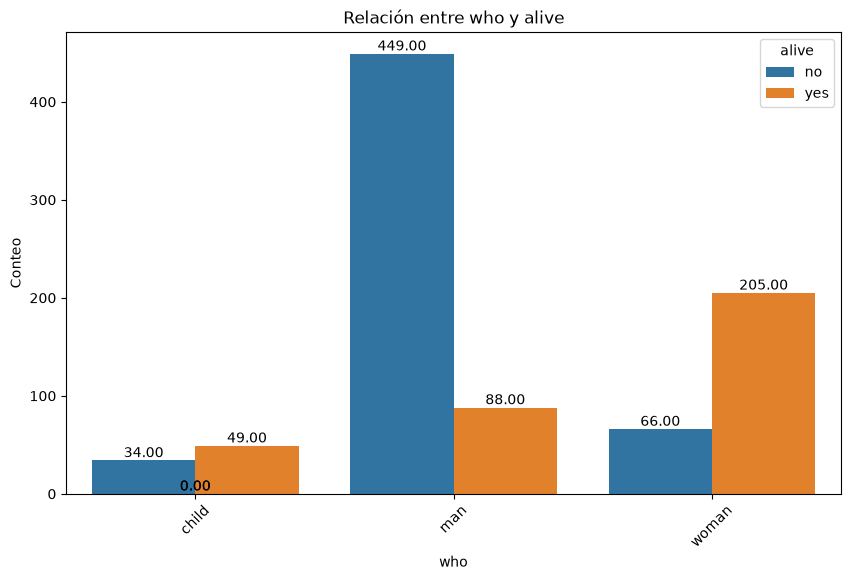

In [11]:
# Frecuencias absolutas: ¿cuántos sobrevivieron de cada grupo?
plot_categorical_relationship_fin(df_titanic, "who", "alive", relative_freq=False, show_values=True)

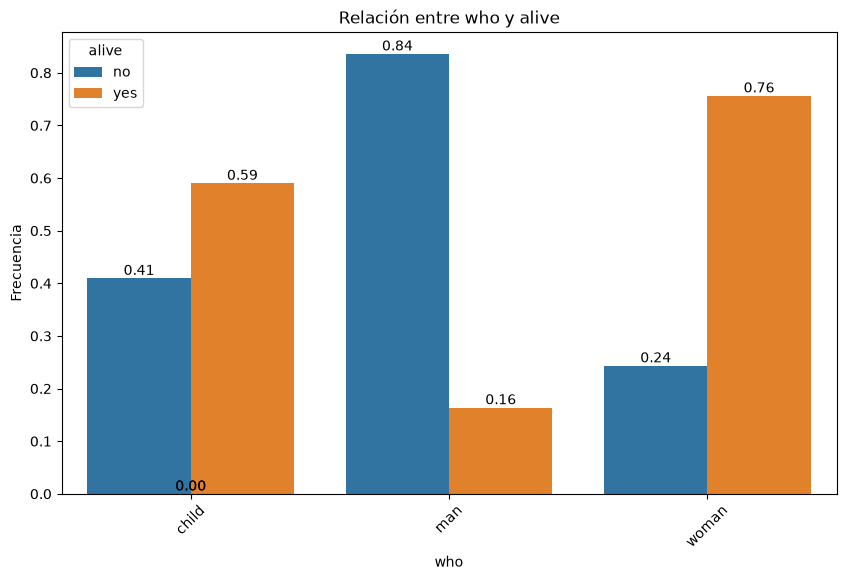

In [12]:
# Frecuencias relativas: ¿qué % de cada grupo sobrevivió?
plot_categorical_relationship_fin(df_titanic, "who", "alive", relative_freq=True, show_values=True)

In [13]:
(pd.crosstab(df_titanic["who"], df_titanic["alive"], normalize="index") * 100).round(1)

alive,no,yes
who,,
child,41.0,59.0
man,83.6,16.4
woman,24.4,75.6


 1. sexo y supervivencia

In [14]:
p = test_chi2(df_titanic, "sex", "alive")
(pd.crosstab(df_titanic["sex"], df_titanic["alive"], normalize="index") * 100).round(1)

alive    no  yes
sex             
female   81  233
male    468  109
p-valor: 1.1973570627755645e-58


alive,no,yes
sex,,
female,25.8,74.2
male,81.1,18.9


**Chi-cuadrado:**
- La **tabla de contingencia** (`pd.crosstab`) cuenta cuántos pasajeros hay en cada combinación (p. ej. mujeres que sobrevivieron).
- `chi2_contingency` compara esa tabla con la que habría **si sexo y supervivencia fueran independientes** (las *frecuencias esperadas*). Cuanto más se alejen, mayor es el **estadístico chi-cuadrado**.
- Los **grados de libertad** son (filas − 1) × (columnas − 1): aquí (2 − 1) × (2 − 1) = 1.
- El **p-valor** es prácticamente 0: si el sexo no influyera, sería practicamente imposible ver una diferencia tan grande por casualidad. Por eso **se rechaza H0**.

2. Adulto o niño. Binaria a partir de `who` (child = niño; man/woman = adulto)

In [15]:
df_titanic["adulto_nino"] = np.where(df_titanic["who"] == "child", "child", "adult")
p = test_chi2(df_titanic, "adulto_nino", "alive")
(pd.crosstab(df_titanic["adulto_nino"], df_titanic["alive"], normalize="index") * 100).round(1)

alive         no  yes
adulto_nino          
adult        515  293
child         34   49
p-valor: 8.005497211300105e-05


alive,no,yes
adulto_nino,,
adult,63.7,36.3
child,41.0,59.0


**Respuesta:**
* **En términos absolutos** sobrevivieron más **mujeres (205)** que hombres (88) y niños (49).
* **En términos relativos** también las **mujeres: 75,6 %** sobrevivieron más, frente al **59,0 % de los niños** y solo el **16,4 % de los hombres**. Un hombre adulto tenía casi 5 veces menos probabilidad de sobrevivir que una mujer. Es el protocolo **"mujeres y niños primero"** en los botes salvavidas.
* **Sexo y supervivencia:** chi-cuadrado con p-valor muy por debajo de 0,05. **Rechazo de la independencia**: hay una relación muy significativa (sobrevivió el 74,2 % de las mujeres frente al 18,9 % de los hombres).
* **Adulto o niño:** p-valor < 0,05. **También hay relación significativa**: sobrevivió el 59 % de los niños frente al 36,3 % de los adultos. La diferencia es más débil que la de sexo, porque el grupo "adulto" mezcla mujeres (mayor supervivencia) y hombres (menor supervivencia).

### Pregunta 2: clase y supervivencia

*`class` (categórica ordinal) frente a `alive` (binaria): **chi-cuadrado**.*

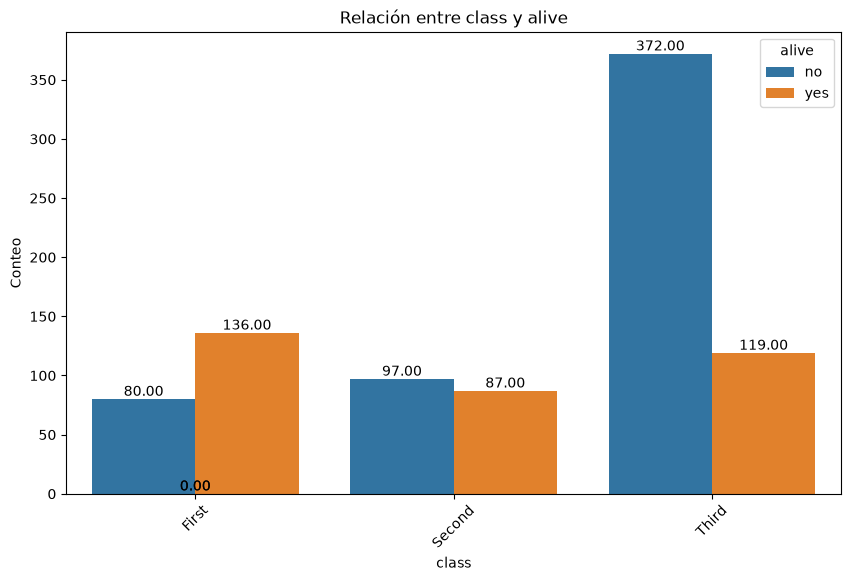

In [16]:
plot_categorical_relationship_fin(df_titanic, "class", "alive", relative_freq=False, show_values=True)

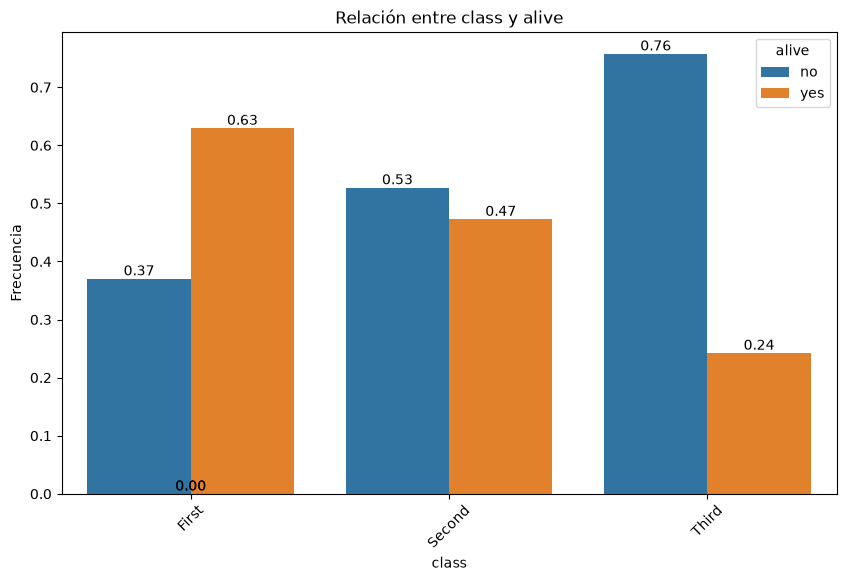

In [17]:
plot_categorical_relationship_fin(df_titanic, "class", "alive", relative_freq=True, show_values=True)

In [18]:
p = test_chi2(df_titanic, "class", "alive")
(pd.crosstab(df_titanic["class"], df_titanic["alive"], normalize="index") * 100).round(1)

alive    no  yes
class           
First    80  136
Second   97   87
Third   372  119
p-valor: 4.549251711298793e-23


alive,no,yes
class,,
First,37.0,63.0
Second,52.7,47.3
Third,75.8,24.2


**Respuesta:**
* **En términos absolutos** sobrevivieron más pasajeros de **primera (136)**, seguidos de cerca por tercera (119) y segunda (87).
* **En términos relativos** la diferencia es mayor: sobrevivió el **63,0 % en primera**, el **47,3 % en segunda** y solo el **24,2 % en tercera**. 
* **Test:** p-valor < 0,05. **Rechazo H0**: la clase y la supervivencia están relacionadas de forma muy significativa. Los camarotes de primera estaban más cerca de la cubierta de botes y los de tercera más abajo y con peor acceso.

### Pregunta 3: ciudad de embarque y supervivencia

*`embark_town` (categórica) frente a `alive` (binaria): **chi-cuadrado**.*

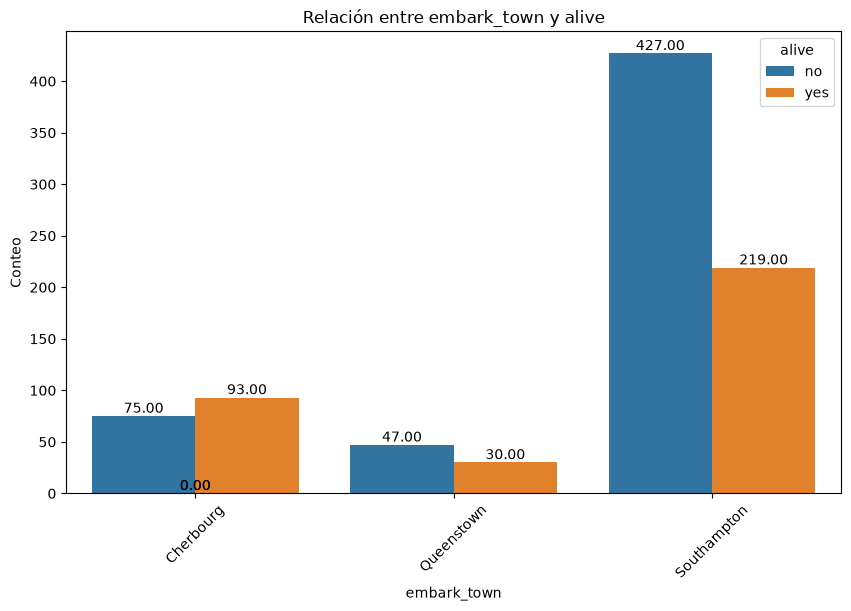

In [19]:
plot_categorical_relationship_fin(df_titanic, "embark_town", "alive", relative_freq=False, show_values=True)

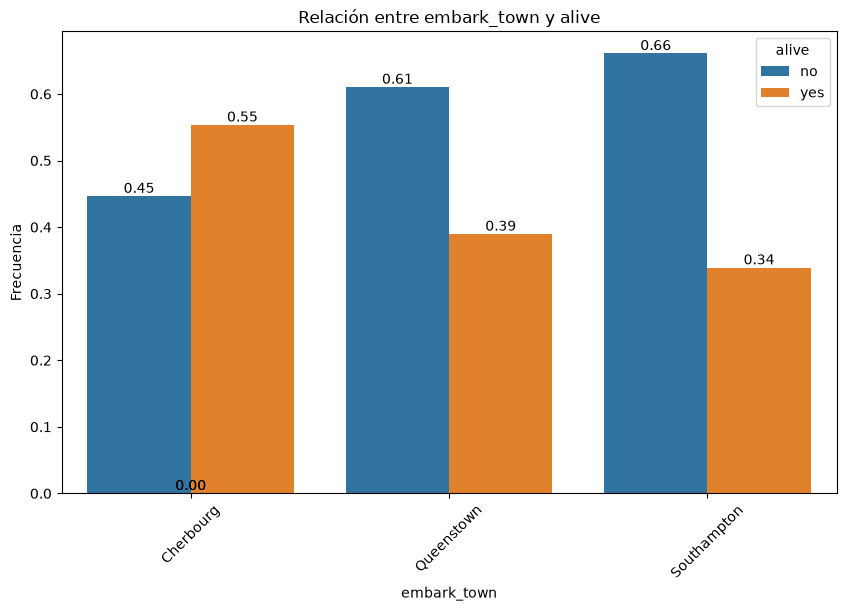

In [20]:
plot_categorical_relationship_fin(df_titanic, "embark_town", "alive", relative_freq=True, show_values=True)

In [21]:
p = test_chi2(df_titanic, "embark_town", "alive")
(pd.crosstab(df_titanic["embark_town"], df_titanic["alive"], normalize="index") * 100).round(1)

alive         no  yes
embark_town          
Cherbourg     75   93
Queenstown    47   30
Southampton  427  219
p-valor: 2.3008626481449577e-06


alive,no,yes
embark_town,,
Cherbourg,44.6,55.4
Queenstown,61.0,39.0
Southampton,66.1,33.9


*La ciudad por sí misma no implica salvar a nadie -> **variable escondida**: ¿qué clase de pasajeros embarcó en cada puerto?*

In [22]:
(pd.crosstab(df_titanic["embark_town"], df_titanic["class"], normalize="index") * 100).round(1)

class,First,Second,Third
embark_town,,,
Cherbourg,50.6,10.1,39.3
Queenstown,2.6,3.9,93.5
Southampton,20.0,25.4,54.6


**Respuesta:**
* **En términos absolutos** sobrevivieron más personas de **Southampton (219)**, porque de allí salió el 72 % del pasaje.
* **En porcentaje** gana **Cherbourg: 55,4 %** en supervivientes, frente al 39,0 % de Queenstown y el 33,9 % de Southampton.
* **Test:** p-valor < 0,05. Estadísticamente **sí hay relación** entre la ciudad de embarque y supervivencia.
* **Pero la relación no es causalidad.** En Cherbourg más de la mitad embarcó en **primera clase**, mientras que en Queenstown el **94 %** iba en tercera. La relación ciudad-supervivencia se explica en gran parte por la **clase** (variable de confusión).

### Pregunta 4: precio del pasaje y supervivencia

`fare` (numérica) frente a `alive` (binaria). Primero el análisis visual y después elijo entre **t de Student** (si las distribuciones parecen campanas de Gauss) o **U de Mann-Whitney**.

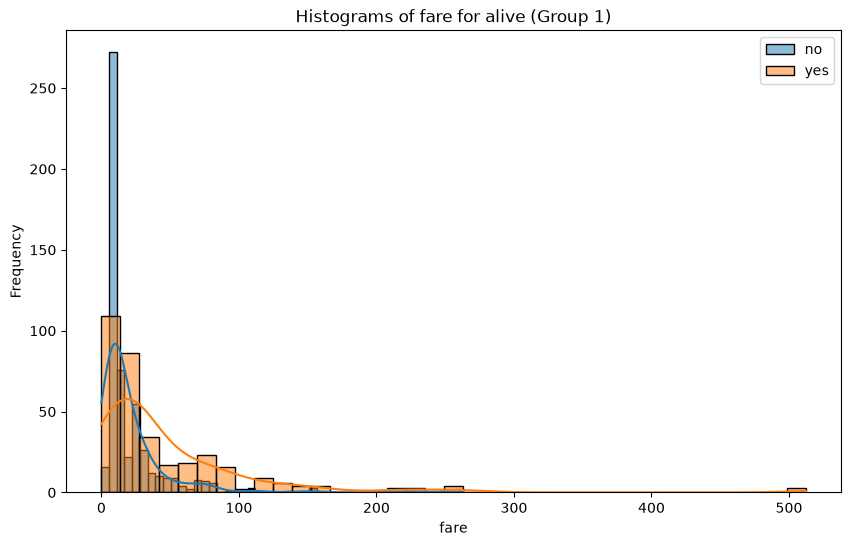

In [23]:
plot_grouped_histograms(df_titanic, "alive", "fare", group_size=2)

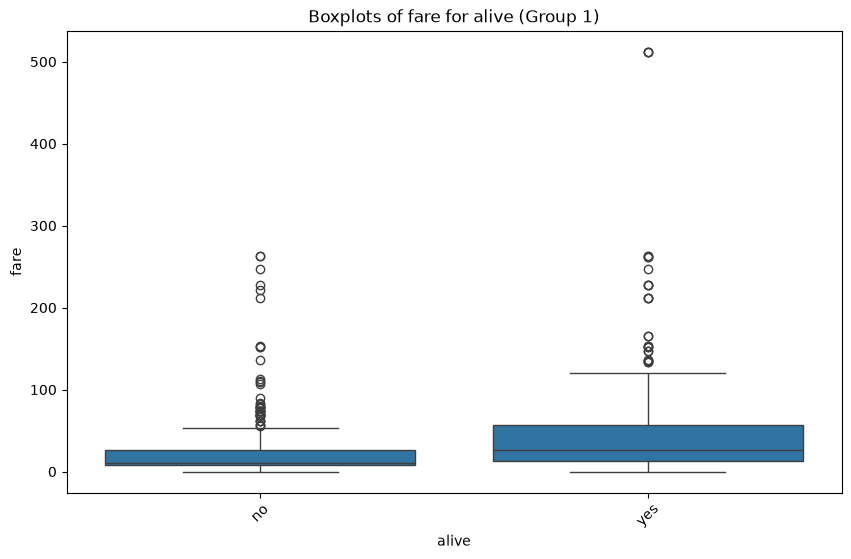

In [24]:
plot_grouped_boxplots(df_titanic, "alive", "fare")

In [25]:
df_titanic.groupby("alive")["fare"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
alive,,,,,,,,
no,549.0,22.12,31.39,0.0,7.85,10.5,26.0,263.00
yes,342.0,48.40,66.60,0.0,12.48,26.0,57.0,512.33


*Las distribuciones **no son gaussianas** (muy asimétricas a la derecha), así que aplico la **U de Mann-Whitney**:*

In [26]:
grupo_vivos = df_titanic.loc[df_titanic["alive"] == "yes", "fare"]
grupo_muertos = df_titanic.loc[df_titanic["alive"] == "no", "fare"]
u_stat, p_valor = mannwhitneyu(grupo_vivos, grupo_muertos)
print("Estadístico U:", u_stat)
print("p-valor:", p_valor)

Estadístico U: 129951.5
p-valor: 4.553477179250237e-22


**Por qué Mann-Whitney y no t de Student:**
- La t de Student compara **medias** y supone que cada grupo tiene forma de **campana (normal)**. Los histogramas de `fare` tienen una cola muy larga a la derecha, así que no se cumple.
- **U de Mann-Whitney** es la alternativa **no paramétrica**: ordena todos los precios de menor a mayor y comprueba si los de un grupo tienden a estar más arriba que los del otro.
- H0: las dos poblaciones (vivos y fallecidos) tienen la misma distribución de precio.**Los supervivientes pagaron significativamente más**.

**Respuesta:**
* Los supervivientes pagaron bastante más: **mediana de 26** frente a **10,5** de los fallecidos (más del doble). La media también se duplica (48,4 frente a 22,1), aunque está inflada por los billetes muy caros.
* En el boxplot la caja de los supervivientes está más arriba y es mucho más ancha. La mayoría de fallecidos se concentra en billetes baratos.
* **Mann-Whitney:** p-valor < 0,05. **Rechazada H0**: el precio pagado y la supervivencia están relacionados de forma significativa.
* El precio es -> un reflejo de la **clase** (y de la ubicación del camarote): pagar más significaba viajar más cerca de los botes.

### Pregunta 5: pasajeros que no pagaron y el billete más caro

In [27]:
gratis = df_titanic[df_titanic["fare"] == 0]
print("Pasajeros con billete a 0:", len(gratis))
gratis

Pasajeros con billete a 0: 15


,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members,adulto_nino
179,male,36.000000,0.0,Third,man,True,Southampton,no,True,0,adult
263,male,40.000000,0.0,First,man,True,Southampton,no,True,0,adult
271,male,25.000000,0.0,Third,man,True,Southampton,yes,True,0,adult
277,male,33.173123,0.0,Second,man,True,Southampton,no,True,0,adult
302,male,19.000000,0.0,Third,man,True,Southampton,no,True,0,adult
413,male,33.173123,0.0,Second,man,True,Southampton,no,True,0,adult
466,male,33.173123,0.0,Second,man,True,Southampton,no,True,0,adult
481,male,33.173123,0.0,Second,man,True,Southampton,no,True,0,adult
597,male,49.000000,0.0,Third,man,True,Southampton,no,True,0,adult
633,male,33.173123,0.0,First,man,True,Southampton,no,True,0,adult


In [28]:
gratis[["sex", "who", "class", "embark_town", "alone", "alive"]].value_counts()

sex   who  class   embark_town  alone  alive
male  man  Second  Southampton  True   no       6
           First   Southampton  True   no       5
           Third   Southampton  True   no       3
                                       yes      1
Name: count, dtype: int64

In [29]:
df_titanic[df_titanic["fare"] == df_titanic["fare"].max()]

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members,adulto_nino
258,female,35.0,512.3292,First,woman,False,Cherbourg,yes,True,0,adult
679,male,36.0,512.3292,First,man,True,Cherbourg,yes,False,1,adult
737,male,35.0,512.3292,First,man,True,Cherbourg,yes,True,0,adult


**Respuesta:**

**Billete a 0 (15 pasajeros).** Los datos muestran un perfil muy homogéneo: **todos son hombres adultos, embarcados en Southampton, que viajaban solos**, y repartidos entre las tres clases. 
Sobrevivió **1 de los 15**. Como parte de la historia, el perfil (hombres solos, todos embarcados en Southampton, en las tres clases) indica que probablemente no eran pasajeros, sino empleados.

**El billete más caro: 512,33.** Lo comparten **3 pasajeros de primera clase embarcados en Cherbourg**: una mujer de 35 años y dos hombres de 35 y 36. Se salvaron.

### Pregunta 6: dinero pagado, ciudad de embarque y supervivencia

Análisis **multivariante** (2 categóricas y 1 numérica). Siguiendo la teoría (Multivariante III), -> una variable directora (`alive`) y comparar la relación `embark_town` - `fare` dentro de cada grupo.

In [30]:
df_titanic.pivot_table(index="embark_town", columns="alive", values="fare", aggfunc=["median", "mean", "count"]).round(1)

median        mean       count     
alive           no   yes    no   yes    no  yes
embark_town                                    
Cherbourg     14.5  56.9  35.4  79.7    75   93
Queenstown     7.8   7.8  13.3  13.2    47   30
Southampton   10.5  26.0  20.7  39.9   427  219

alive = no


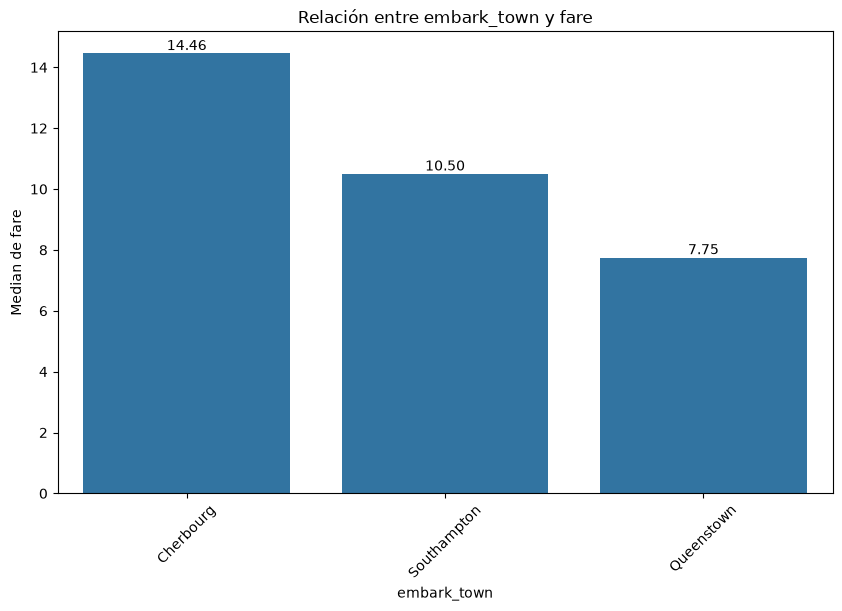

alive = yes


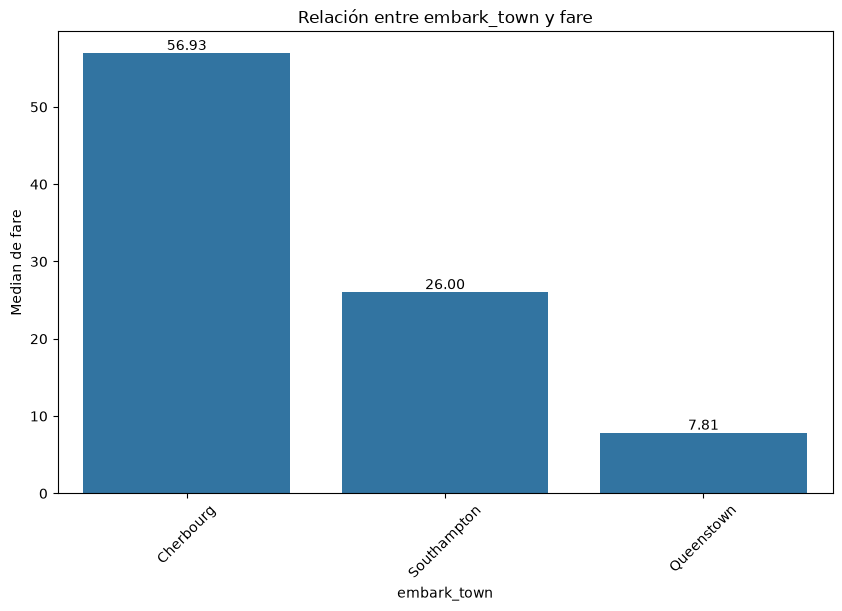

In [31]:
# Relación ciudad-precio por cada valor de la variable (alive)
for valor in df_titanic["alive"].unique():
    print(f"alive = {valor}")
    plot_categorical_numerical_relationship(df_titanic[df_titanic["alive"] == valor], "embark_town", "fare", show_values=True, measure="median")

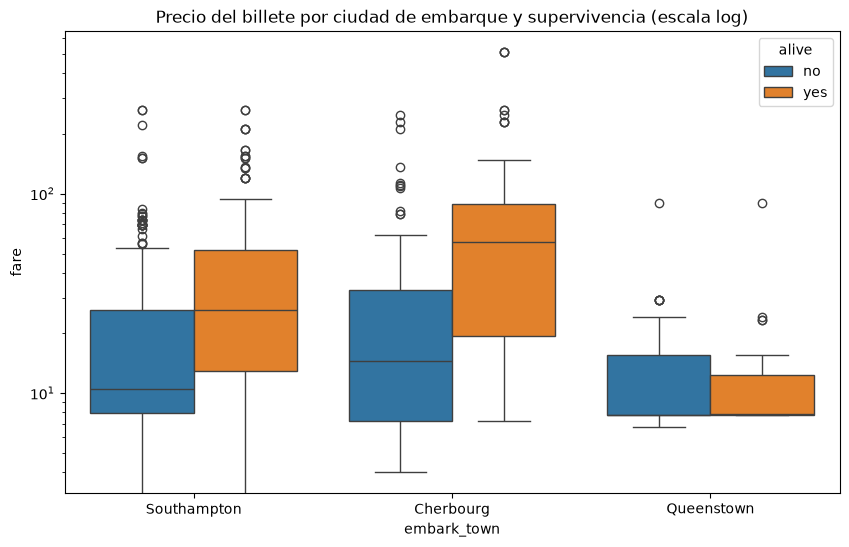

In [32]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_titanic, x="embark_town", y="fare", hue="alive")
plt.yscale("log")  # escala logarítmica para que los billetes muy caros permitan visualizar el resto
plt.title("Precio del billete por ciudad de embarque y supervivencia (escala log)")
plt.show()

**Respuesta:**
* **Cherbourg** es la ciudad de los billetes más caros: los supervivientes de allí pagaron una mediana de **56,9** (media 79,7), frente a 14,5 de los fallecidos de la misma ciudad.
* **Southampton** sigue el mismo patrón, a menor escala: los supervivientes pagaron una mediana de **26** frente a **10,5** de los fallecidos.
* **Queenstown** es la excepción: casi todos sus pasajeros iban en tercera y pagaron lo mismo, **mediana 7,8** sobrevivieran o no. Como el precio no varía, no puede marcar diferencia.
* **Conclusión:** en las ciudades donde hubo pasajeros de primera (Cherbourg y Southampton), **haber pagado más se asocia con sobrevivir**. La ciudad influye a través del tipo de pasajero (y de dinero) que embarcó en ella.

### Pregunta 7: clase, edad y supervivencia

Para poder agrupar, convierto `age` en una categórica por tramos (`grupo_edad`). Después hago el multivariante con la **clase como variable directora**: separo el dataset por clase y en cada subconjunto analizo `grupo_edad` - `alive`.

In [33]:
bins = [0, 12, 18, 30, 45, 60, 81]
etiquetas = ["0-12", "13-18", "19-30", "31-45", "46-60", "61+"]
df_titanic["grupo_edad"] = pd.cut(df_titanic["age"], bins=bins, labels=etiquetas, include_lowest=True)
df_titanic["grupo_edad"].value_counts().sort_index()

grupo_edad
0-12      69
13-18     70
19-30    270
31-45    379
46-60     81
61+       22
Name: count, dtype: int64

Clase: First


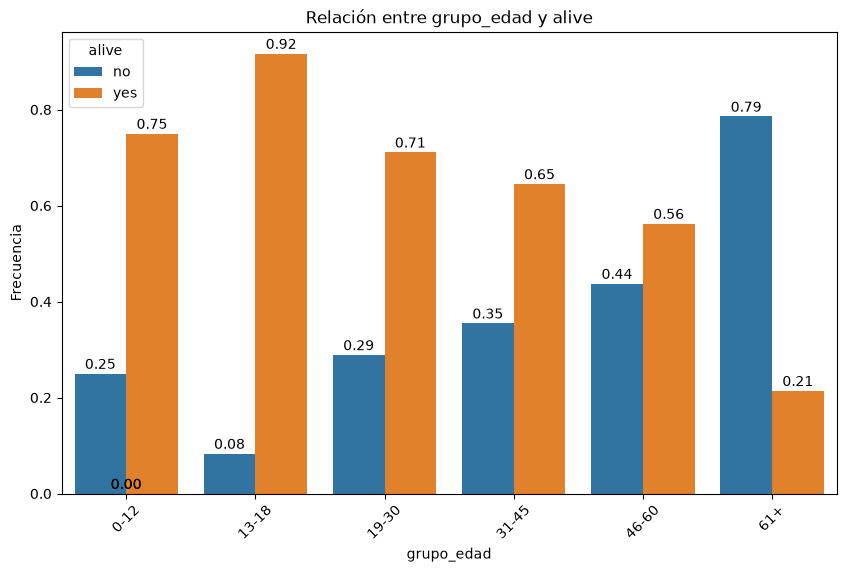

Clase: Second


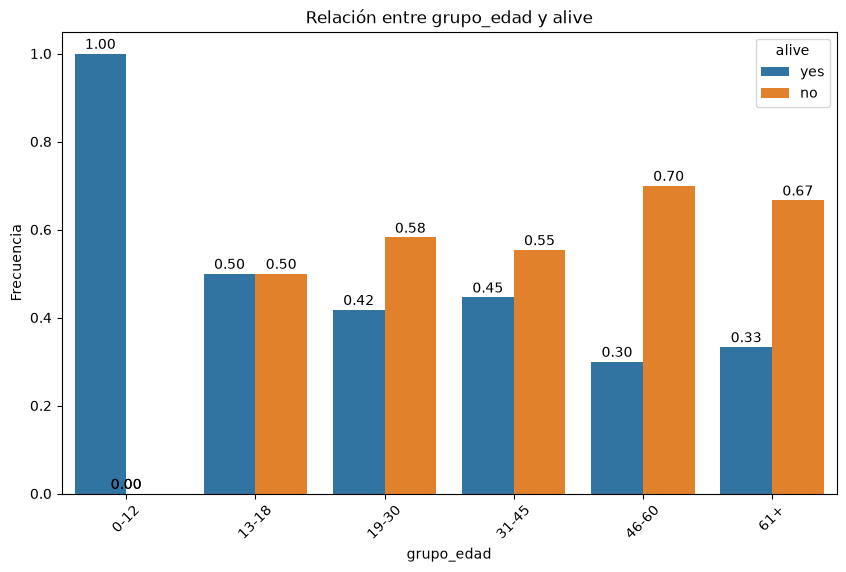

Clase: Third


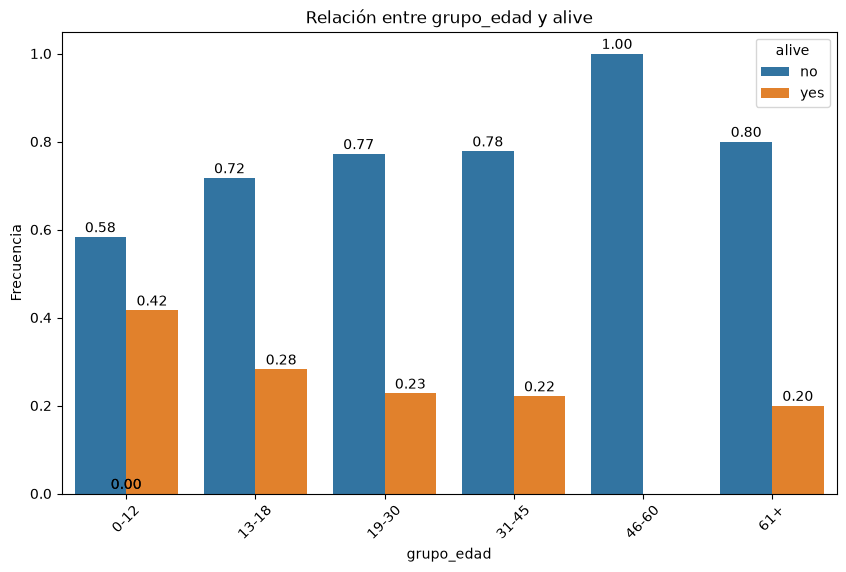

In [34]:
col_directora = "class"
diccionario_multivariante = {}
for valor in ["First", "Second", "Third"]:
    diccionario_multivariante[valor] = df_titanic.loc[df_titanic[col_directora] == valor, ["grupo_edad", "alive"]]

for valor, df_datos in diccionario_multivariante.items():
    print(f"Clase: {valor}")
    plot_categorical_relationship_fin(df_datos, "grupo_edad", "alive", relative_freq=True, show_values=True, size_group=6)

In [35]:
tabla = pd.crosstab([df_titanic["class"], df_titanic["grupo_edad"]], df_titanic["alive"])
tabla["total"] = tabla["yes"] + tabla["no"]
tabla["% supervivencia"] = (tabla["yes"] / tabla["total"] * 100).round(1)
print("Top 5 en términos ABSOLUTOS (nº de supervivientes):")
display(tabla.sort_values("yes", ascending=False).head(5))
print("Top 5 en términos RELATIVOS (% de supervivencia):")
display(tabla.sort_values("% supervivencia", ascending=False).head(5))

Top 5 en términos ABSOLUTOS (nº de supervivientes):


alive               no  yes  total  % supervivencia
class  grupo_edad                                  
First  31-45        33   60     93             64.5
Third  31-45       172   49    221             22.2
       19-30       122   36    158             22.8
First  19-30        13   32     45             71.1
Second 31-45        36   29     65             44.6

Top 5 en términos RELATIVOS (% de supervivencia):


alive              no  yes  total  % supervivencia
class  grupo_edad                                 
Second 0-12         0   17     17            100.0
First  13-18        1   11     12             91.7
       0-12         1    3      4             75.0
       19-30       13   32     45             71.1
       31-45       33   60     93             64.5

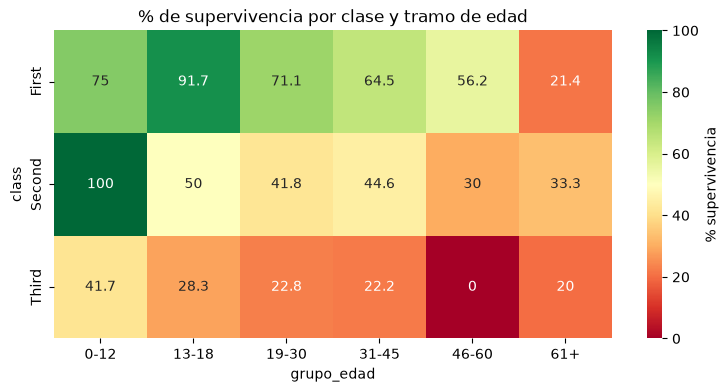

In [36]:
# Vista global: % de supervivencia por clase y tramo de edad
pivot = tabla["% supervivencia"].unstack()
plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt="g", cmap="RdYlGn", cbar_kws={"label": "% supervivencia"})
plt.title("% de supervivencia por clase y tramo de edad")
plt.show()

# fmt="g" -> muestra los números en formato normal, sin ceros de más

**Respuesta:**
* **En términos absolutos**, la agrupación con más supervivientes es **primera clase y 31-45 años (60 personas)**. Le siguen tercera 31-45 (49) y tercera 19-30 (36). El tramo 31-45 puede estar inflado porque la aplicación de la media puso unos 33 años a todos los hombres y mujeres sin edad.
* **En términos relativos**, la mayor es **segunda clase y 0-12 años: sobrevivieron el 100 % (17 de 17 niños)**. Después vienen los adolescentes de primera (13-18: 91,7 %) y los niños de primera (75 %).
* **Patrón:** dentro de cada clase los niños sobreviven más, pero **la clase tiene gran importancia**. Los niños de tercera sobrevivieron solo un 41,7 %, menos que los adultos de 19-45 de primera. En tercera, ningún tramo adulto supera el 30 %. Los mayores de 60 tienen la supervivencia más baja en primera clase. En segunda y tercera el tramo más bajo es el de 46-60 (en tercera no sobrevivió ninguno de los 13).
* Algunos grupos tienen muy pocos casos, como primera 0-12 con 4 niños, esos porcentajes son poco fiables.

### Pregunta 8: edad, precio del billete y supervivencia

*Dos numéricas (`age`, `fare`) y una binaria (`alive`). Primero miro la relación entre las numéricas (dispersión + Pearson) y luego por supervivencia.*

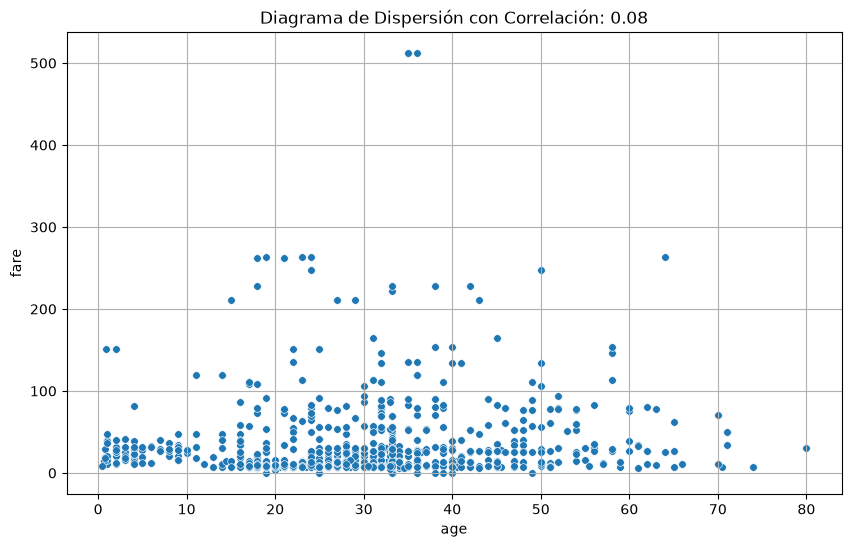

In [37]:
grafico_dispersion_con_correlacion(df_titanic, "age", "fare", tamano_puntos=30, mostrar_correlacion=True)

In [38]:
print("Pearson :", pearsonr(df_titanic["age"], df_titanic["fare"]))
print("Spearman:", spearmanr(df_titanic["age"], df_titanic["fare"]))  

Pearson : PearsonRResult(statistic=np.float64(0.08076504311672364), pvalue=np.float64(0.015893067264095676))
Spearman: SignificanceResult(statistic=np.float64(0.09052375551398675), pvalue=np.float64(0.006853920955657849))


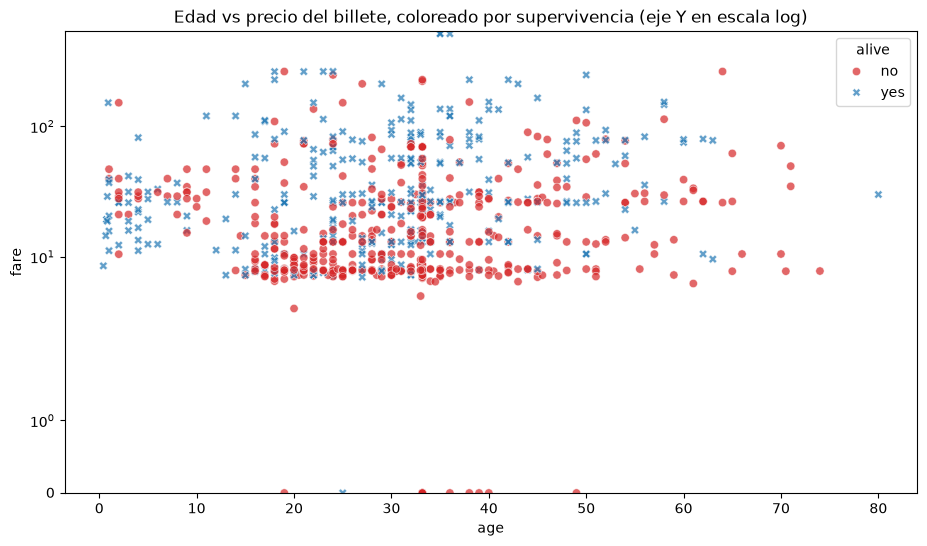

In [39]:
plt.figure(figsize=(11, 6))
sns.scatterplot(data=df_titanic, x="age", y="fare", hue="alive", style="alive", alpha=0.7, palette={"yes": "tab:blue", "no": "tab:red"})
plt.yscale("symlog")  # escala logarítmica
plt.ylim(bottom=0)
plt.title("Edad vs precio del billete, coloreado por supervivencia (eje Y en escala log)")
plt.show()

In [40]:
df_titanic.groupby("alive")[["age", "fare"]].median()

,age,fare
alive,,
no,32.0,10.5
yes,31.0,26.0


**Respuesta:**
* **Edad y precio apenas están relacionados**. Aunque el p-valor sale < 0,05 (con 891 datos, hasta una relación muy pequeña resulta "significativa"), la fuerza es **casi nula**. Los mayores no pagaban realmente más.
* Supervivencia, **el eje que separa es el del precio, no el de la edad**: en la franja de billetes baratos dominan los puntos rojos (fallecidos) a cualquier edad, y a medida que sube el precio aumenta la proporción de azules; con billetes de menos de 15 sobrevivió solo el 25 %, entre 50 y 100 el 65 % y por encima de 100 el 74 %.
* La edad solo marca diferencia en el extremo izquierdo: **los niños pequeños sobreviven bastante incluso con billetes baratos**. Las medianas de edad de vivos y fallecidos son casi iguales (31 frente a 32), mientras que las de precio se duplican (26 frente a 10,5).
* **Conclusión global del Titanic:** la supervivencia la explican sobre todo **el sexo/tipo de pasajero ("mujeres y niños primero")** y **la posición socioeconómica (clase/precio)**. La ciudad de embarque y la edad adulta influyen poco por sí mismas.

## #2 Viajes

El objetivo en este caso no es tanto hacer un montón de análisis sino entender cómo de un dataset podemos obtener preguntas o hipótesis interesantes (si las hay)

### #2.1 

Carga el dataset de viajes del mes de junio. Repite el análisis bivariante entre las variables "Aircompany" e "Ingresos", mostrando previamente los viajes por compañía aérea. ¿Qué situación llamativa nos surgió? (Ten en cuenta que somos el departamenteo de DataScience de TabarAir)

In [ ]:
# El dataset de viajes de junio -> dataset_viajes_A.csv (todos los registros son del mes Jun23).

df_viajes = pd.read_csv(ruta_datos + "dataset_viajes_A.csv")
df_viajes.info()
df_viajes.head()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   aircompany  600 non-null    str    
 1   origen      600 non-null    str    
 2   destino     600 non-null    str    
 3   distancia   600 non-null    int64  
 4   avion       600 non-null    str    
 5   con_escala  600 non-null    bool   
 6   consumo_kg  600 non-null    float64
 7   duracion    600 non-null    int64  
 8   ingresos    600 non-null    float64
 9   id_vuelo    600 non-null    str    
 10  mes         600 non-null    str    
dtypes: bool(1), float64(2), int64(2), str(6)
memory usage: 47.6 KB


,aircompany,origen,destino,distancia,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes
0,Airnar,París,Ginebra,411,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23
1,FlyQ,Bali,Roma,12738,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23
2,TabarAir,Ginebra,Los Angeles,9103,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23
3,MoldaviAir,París,Cincinnati,6370,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23
4,TabarAir,Cincinnati,Roma,7480,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23


*Univariante previo: nº de viajes por compañía (frecuencias absolutas y relativas)*

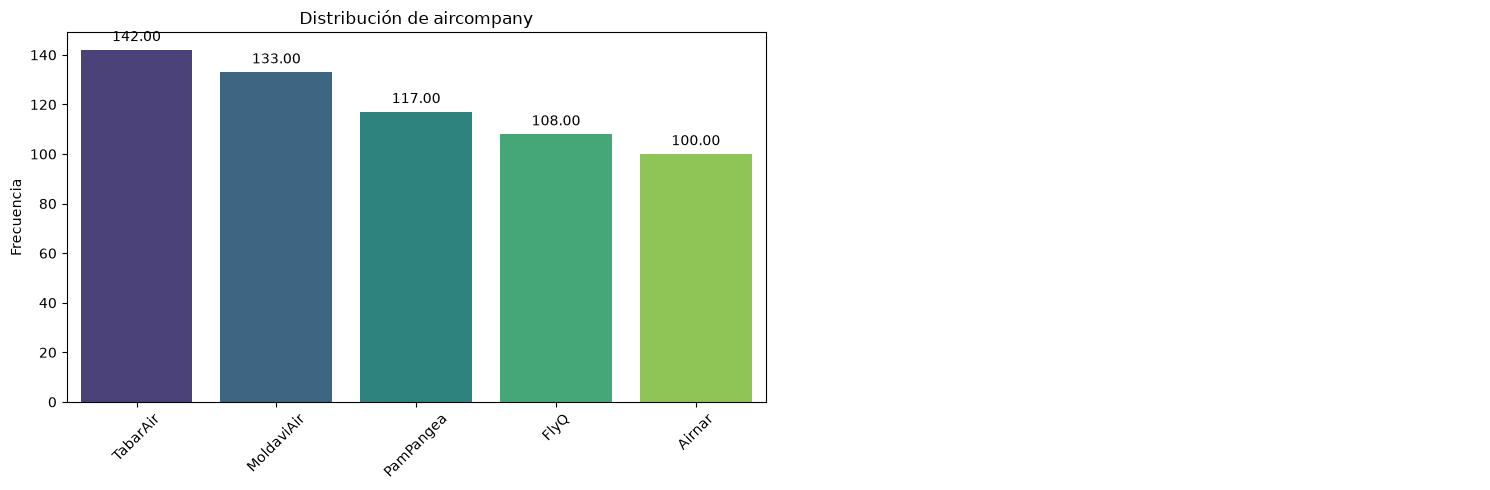

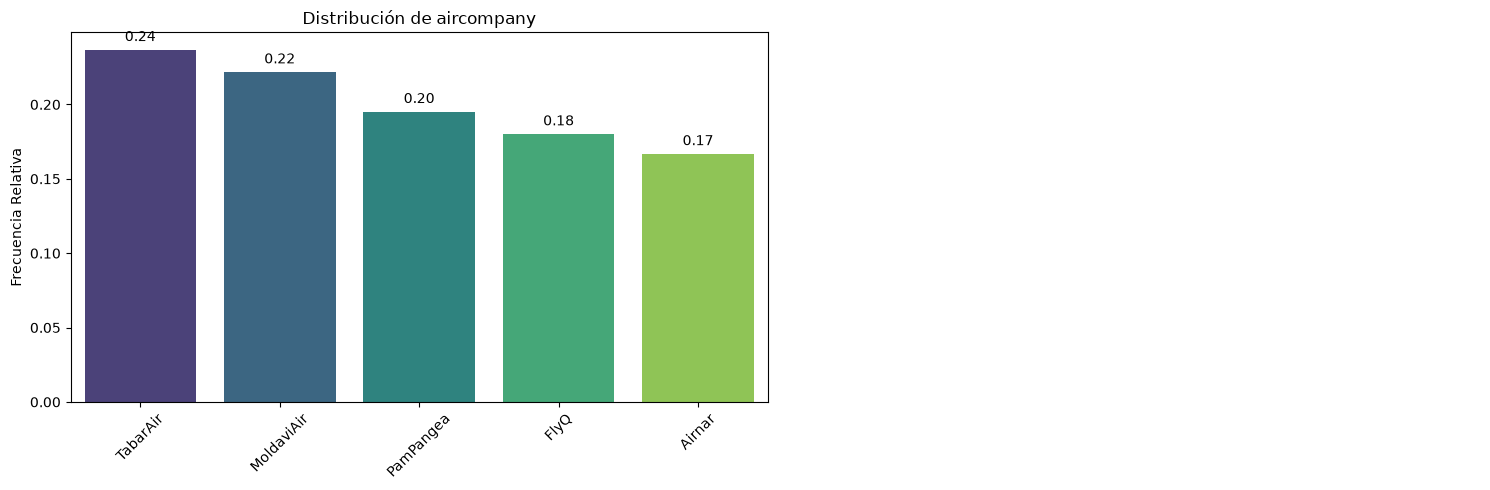

In [42]:
pinta_distribucion_categoricas(df_viajes, ["aircompany"], relativa=False, mostrar_valores=True)
pinta_distribucion_categoricas(df_viajes, ["aircompany"], relativa=True, mostrar_valores=True)

Bivariante categórica-numérica `aircompany` - `ingresos`: medidas de tendencia por grupo, boxplots y al ser más de 2 grupos, **ANOVA**.

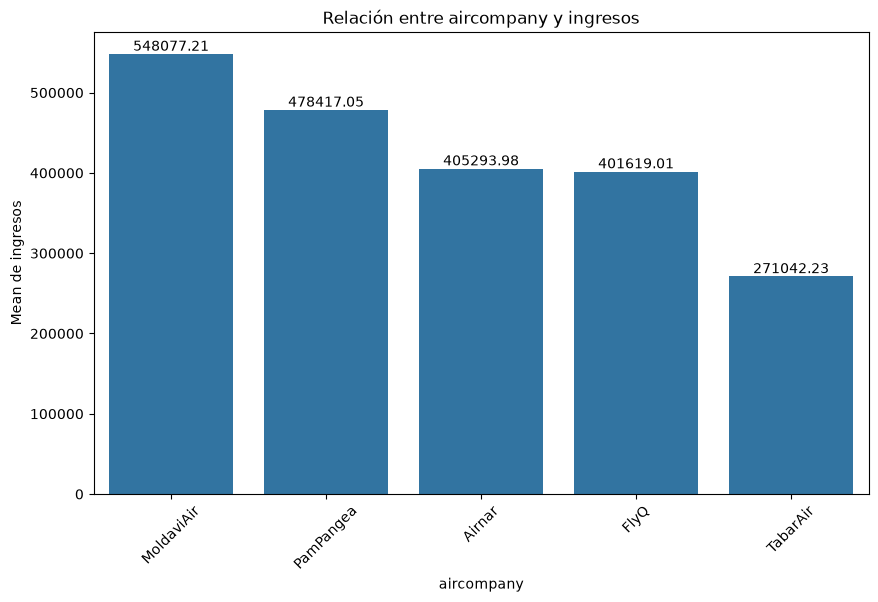

In [43]:
plot_categorical_numerical_relationship(df_viajes, "aircompany", "ingresos", show_values=True, measure="mean")

In [44]:
resumen_cia = df_viajes.groupby("aircompany").agg(n_viajes=("ingresos", "size"),
                                                  ingresos_totales=("ingresos", "sum"),
                                                  ingreso_medio=("ingresos", "mean"),
                                                  ingreso_mediano=("ingresos", "median")).sort_values("n_viajes", ascending=False)
resumen_cia["% viajes"] = (resumen_cia["n_viajes"] / resumen_cia["n_viajes"].sum() * 100).round(1)
resumen_cia["% ingresos"] = (resumen_cia["ingresos_totales"] / resumen_cia["ingresos_totales"].sum() * 100).round(1)
resumen_cia.round(1)

,n_viajes,ingresos_totales,ingreso_medio,ingreso_mediano,% viajes,% ingresos
aircompany,,,,,,
TabarAir,142,38487996.7,271042.2,258379.7,23.7,15.3
MoldaviAir,133,72894268.8,548077.2,532426.2,22.2,29.0
PamPangea,117,55974794.7,478417.0,442668.5,19.5,22.3
FlyQ,108,43374852.9,401619.0,366970.7,18.0,17.3
Airnar,100,40529397.8,405294.0,396764.2,16.7,16.1


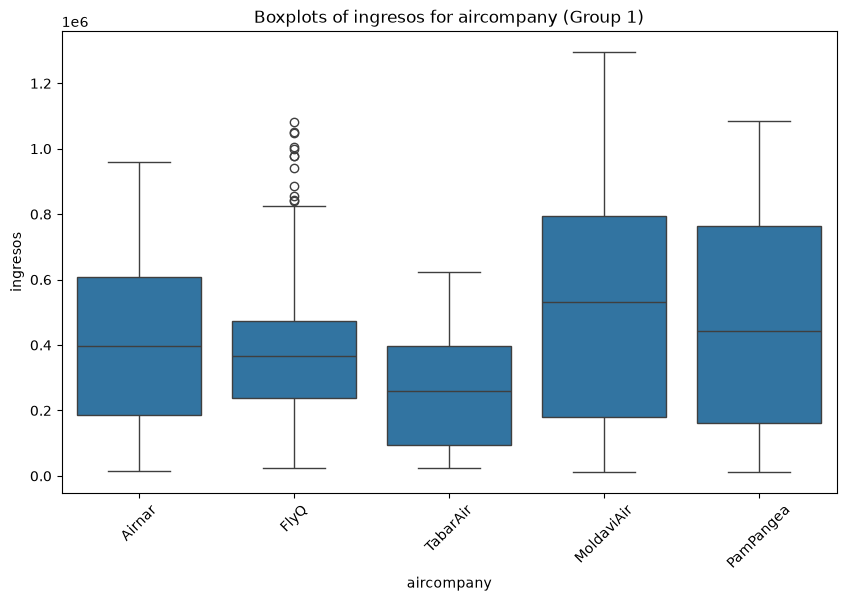

ANOVA -> F: 15.686872918809376 | p-valor: 3.267745855664007e-12


In [45]:
plot_grouped_boxplots(df_viajes, "aircompany", "ingresos")
grupos = [df_viajes.loc[df_viajes["aircompany"] == c, "ingresos"] for c in df_viajes["aircompany"].unique()]
f_val, p_val = f_oneway(grupos[0], grupos[1], grupos[2], grupos[3], grupos[4])
print("ANOVA -> F:", f_val, "| p-valor:", p_val)

**Situación:** **TabarAir es la compañía que más viajes hace (142, el 23,7 %) y, a la vez, la que menos ingresa**: 38,5 M en total (el 15,3 %, la cifra más baja de las cinco) y un ingreso medio por viaje de **271.000**, frente a los 400.000-550.000 del resto. MoldaviAir, con 9 viajes menos, ingresa casi el doble.
El ANOVA confirma que el ingreso por viaje **depende de la compañía de forma significativa**

### #2.2

Repite el análisis multivariante entre "ingresos","distancias" y "consumo_kg". ¿Qué veíamos que parecía también muy prometedor?

In [46]:
df_viajes[["ingresos", "distancia", "consumo_kg"]].corr().round(2)

,ingresos,distancia,consumo_kg
ingresos,1.00,0.93,0.94
distancia,0.93,1.00,0.76
consumo_kg,0.94,0.76,1.00


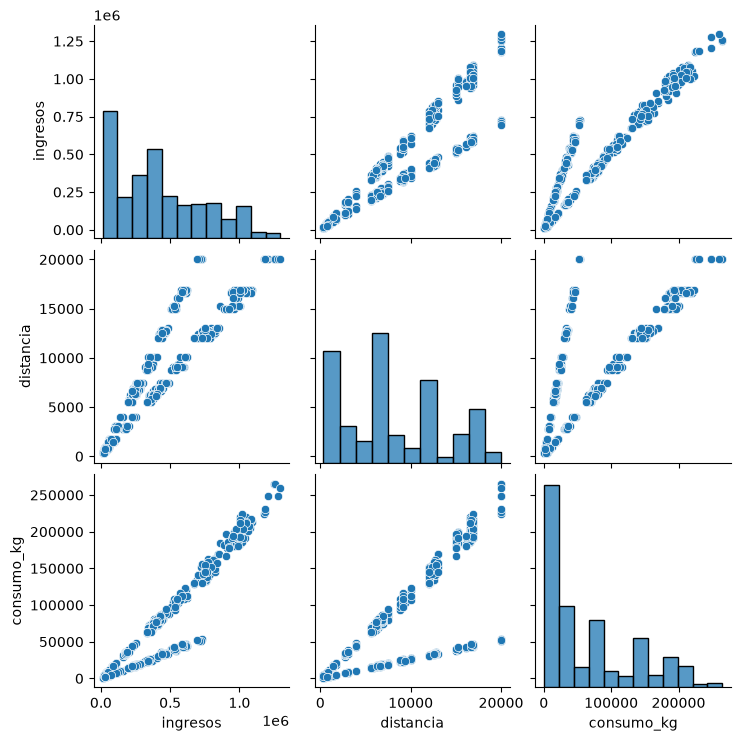

In [47]:
sns.pairplot(df_viajes[["ingresos", "distancia", "consumo_kg"]])
plt.show()

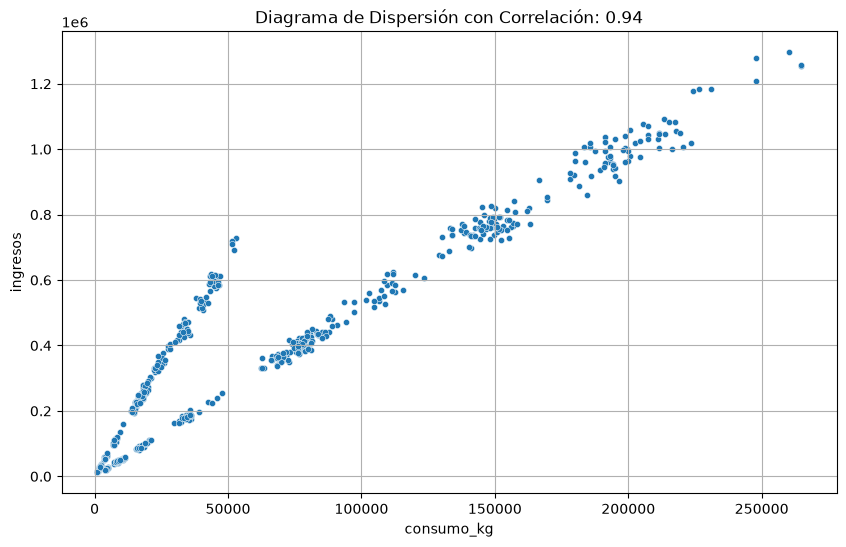

In [48]:
grafico_dispersion_con_correlacion(df_viajes, "consumo_kg", "ingresos", tamano_puntos=20, mostrar_correlacion=True)

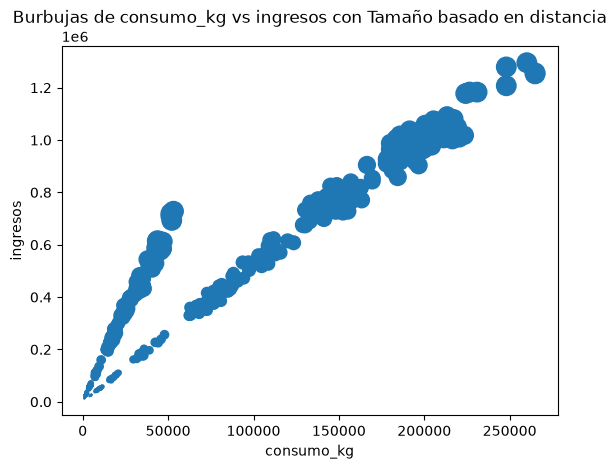

In [49]:
bubble_plot(df_viajes, "consumo_kg", "ingresos", "distancia", scale=100)


* Las tres variables están **muy correlacionadas** (ingresos-consumo r = 0,94, ingresos-distancia r = 0,93, distancia-consumo r = 0,76). Más distancia implica más consumo y más ingresos.
* El diagrama consumo-ingresos: los puntos **no forman una sola nube, sino dos "rectas" bien separadas**. Para el mismo combustible consumido, una línea de vuelos **ingresa mucho más** (vuelos eficientes) que la otra. El pairplot muestra lo mismo en distancia-consumo: dos líneas, una que consume poco por km y otra que consume mucho.
* Hay dos "tipos" de vuelo con eficiencias muy distintas.

### #2.3

Crea una variable categorica "cat_vuelo" a partir de distancias, escoge los rangos de las categorías basándote en la distribución de valores de "distancia" (sugerencia entre 3 y 4 categorías). Extra: Realiza ahora otra vez el análisis multivariante "cat_vuelo", "ingresos", "consumo_kg". ¿Ves algo diferente?

(2,)


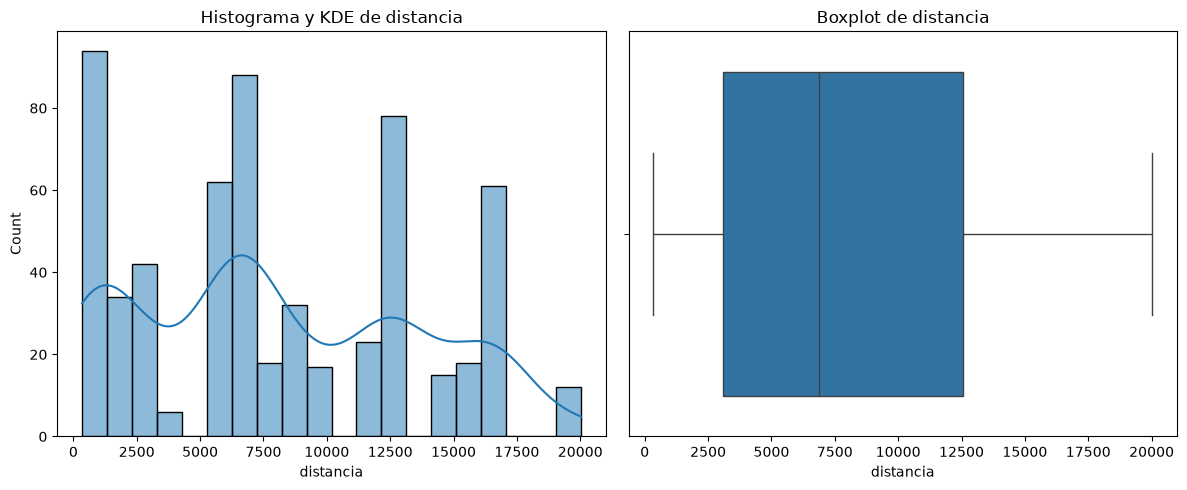

count      600.000000
mean      8071.003333
std       5550.244086
min        344.000000
25%       3073.000000
50%       6877.000000
75%      12553.000000
max      20029.000000
Name: distancia, dtype: float64

In [50]:
plot_combined_graphs(df_viajes, ["distancia"], bins=20)
df_viajes["distancia"].describe()

El histograma no es continuo: hay **huecos sin vuelos** (4.000-5.500 km, 10.100-12.000 km y 13.100-15.000 km) 


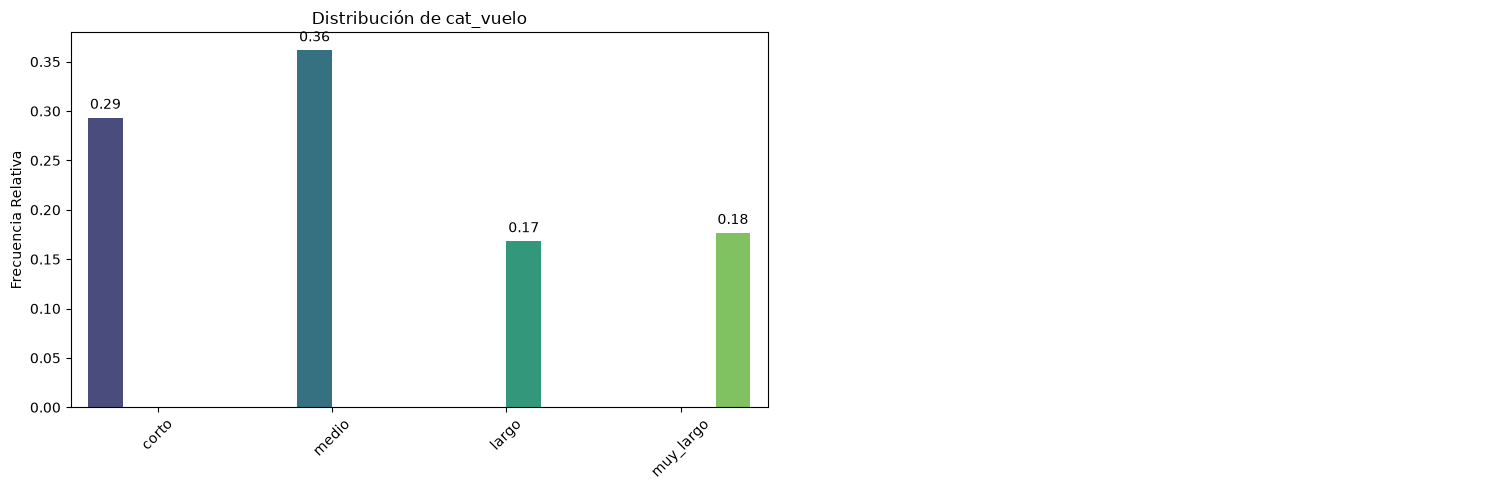

In [51]:
cortes = [0, 4500, 10500, 13500, np.inf]
etiquetas_vuelo = ["corto", "medio", "largo", "muy_largo"]
df_viajes["cat_vuelo"] = pd.cut(df_viajes["distancia"], bins=cortes, labels=etiquetas_vuelo)
pinta_distribucion_categoricas(df_viajes, ["cat_vuelo"], relativa=True, mostrar_valores=True)

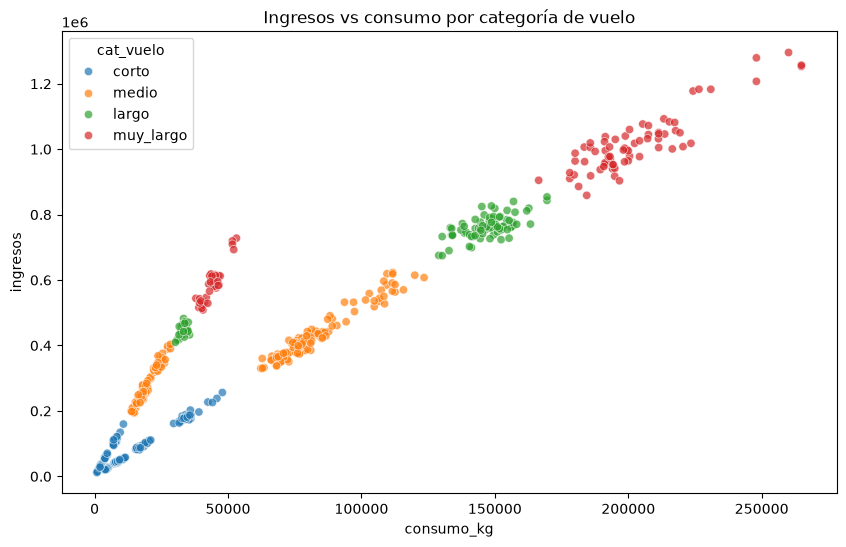

,distancia,consumo_kg,ingresos
cat_vuelo,,,
corto,911.0,7347.0,51958.0
medio,6877.0,66156.0,360338.0
largo,12553.0,143883.0,752213.0
muy_largo,16674.0,191188.0,960057.0


In [52]:
# multivariante ->  cat_vuelo - consumo_kg - ingresos

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_viajes, x="consumo_kg", y="ingresos", hue="cat_vuelo", alpha=0.7)
plt.title("Ingresos vs consumo por categoría de vuelo")
plt.show()
df_viajes.groupby("cat_vuelo")[["distancia", "consumo_kg", "ingresos"]].median().round(0)

Cada categoría de distancia ocupa un tramo de la nube (los cortos abajo a la izquierda, los muy largos arriba a la derecha), pero **las dos rectas de eficiencia aparecen en todas las categorías**: hay vuelos cortos eficientes e ineficientes, y lo mismo con los largos. Por tanto, **la eficiencia no la explica la distancia**. Tiene que ser otra variable (tipo de avión, compañía...).
Además, los vuelos muy largos ingresan mucho más.

### Extra:

#1 Consejos para encontrar "objetivos":

Si partes de un dataset que te parece interesante pero sin pregruntras claras, haz como hicimos con el dataset de Aviones. Describe, prioriza a ojo tus variables, realiza un análisis univariante completo, realiza un análisis bivariante ente las parejas de variables que te parecieron más intereantes. Llegados a este punto si el dataset tiene riqueza informativa, algo diferente tiene que haber aparecido (otra cosa es que sea interesante para ti :-)).  

Fíjate en lo que encontramos en el dataset de viajes: la empresa de más vuelos es la que menos ingresos tiene o la existencia clara de una línea de vuelos más eficientes en consumo que otros y otra de mayor ingresos por consumo. Lo siguiente es explorar esos puntos normalmente intentando contestar a: ¿por qué pasa?¿dónde,cuándo o cómo pasa?  

Busca esas "notas discordantes" en tu dataset, ya de por sí son mensajes del análisis. Ordénalas por importancia (importancia = impactan en ingresos, impactan en la calidad de la vida de las personas, impactan en el coste y poco más hay) e intenta entender por qué suceden esas notas discordantes, cómo solucionarlas o aprovecharlas y ya tienes objeetivos para el EDA; incluso si no encuentras respuesta siempre tendras esas notas discordantes, la conclusión de que no se puede avanzar con los datos que se tienen y los próximos pasos de encontrar más información para explicar lo que ocurre.

#2 Contestando a las preguntas de "Viajes".

- Necesitamos identificar esas líneas eficientes, para ello crea una variable que mida el ingreso por kilogramo consumido y otra que mida el kilogramo consumido por kilómetro. Haz el análisis univariante de las mismas intentando encontrar una diferencia clara entre viajes eficientes y no eficientes (que sabemos que existe). Fija un umbral para indicar si un viaje es supereficiente o si no lo es
- Crea esa variable de eficiencia binaria de eficiencia.
- Ahora haz el análisis bivariante de esa eficiencia y las compañías aéreas (queremos ver si realmente eso explica la situación de TabarAir). 
- Para nota: Hacer los análisis multivariante por compañía, eficiencia, tipo de avión y compañía, eficiencia, destino e incluso el de compañía, eficiencia, origen, destino.
- Con todo ello deberías poder encontrar si hay respuesta a la situación de TabarAir además de poder mostrar otros datos interesantes.

### Extra 2: eficiencia y la situación de TabarAir

(2, 2)


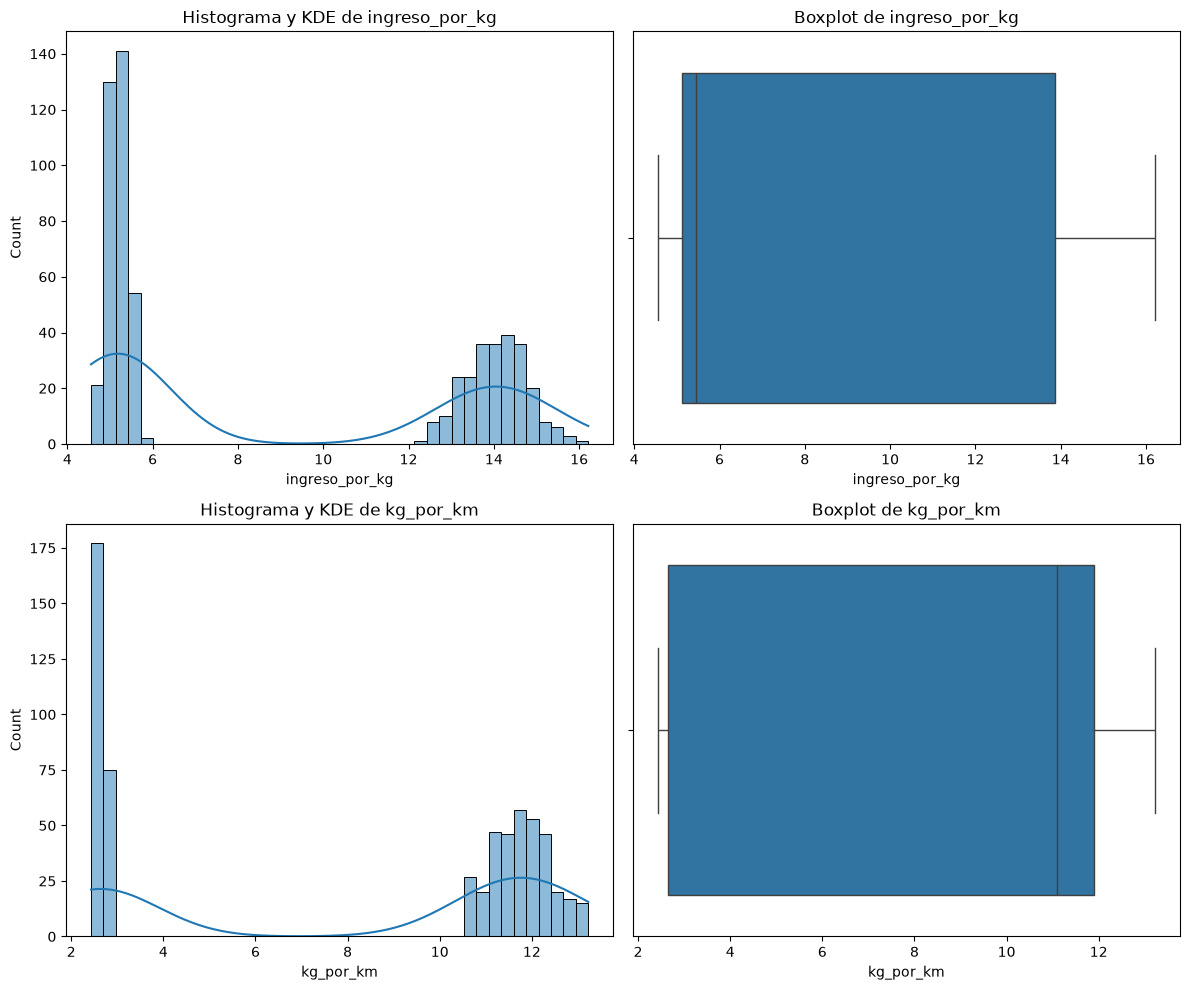

,ingreso_por_kg,kg_por_km
count,600.00,600.00
mean,8.90,7.93
std,4.41,4.54
min,4.55,2.43
25%,5.13,2.66
50%,5.46,11.09
75%,13.86,11.91
max,16.21,13.22


In [ ]:
df_viajes["ingreso_por_kg"] = df_viajes["ingresos"] / df_viajes["consumo_kg"]   # € ingresados por kg de combustible
df_viajes["kg_por_km"] = df_viajes["consumo_kg"] / df_viajes["distancia"]       # kg consumidos por km de vuelo
plot_combined_graphs(df_viajes, ["ingreso_por_kg", "kg_por_km"], bins=40)
df_viajes[["ingreso_por_kg", "kg_por_km"]].describe().round(2)

Ambas variables son **bimodales**
* `ingreso_por_kg`: un grupo entre 4,5 y 5,7 y otro entre 12 y 16. No hay ningún vuelo entre 6 y 12.
* `kg_por_km`: un grupo en 2,5 y otro entre 10,5 y 13.

Umbral en mitad del hueco: **ingreso_por_kg >= 9 → vuelo supereficiente**

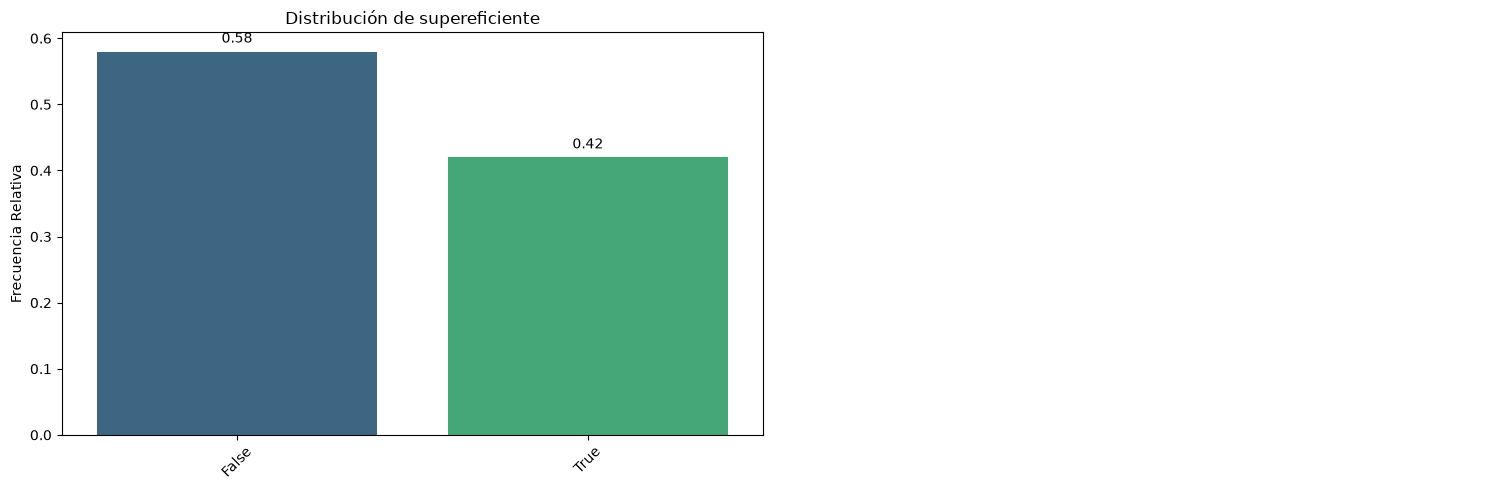

In [54]:
umbral = 9
df_viajes["supereficiente"] = df_viajes["ingreso_por_kg"] >= umbral
pinta_distribucion_categoricas(df_viajes, ["supereficiente"], relativa=True, mostrar_valores=True)

In [55]:
# con el tipo de avión

pd.crosstab(df_viajes["avion"], df_viajes["supereficiente"])

supereficiente,False,True
avion,,
Airbus A320,0,101
Airbus A380,165,0
Boeing 737,0,151
Boeing 747,183,0


In [56]:
df_viajes.groupby("avion")[["ingreso_por_kg", "kg_por_km"]].median().round(2)

,ingreso_por_kg,kg_por_km
avion,,
Airbus A320,14.53,2.71
Airbus A380,5.12,12.25
Boeing 737,13.70,2.60
Boeing 747,5.23,11.31


*Los **Airbus A320 y Boeing 737** (aviones de pasillo único) son supereficientes (14 € por kg y 2,6 kg/km), y todos los **Airbus A380 y Boeing 747** (grandes, de fuselaje ancho) no lo son (5 € por kg y 11-12 kg/km). Las dos rectas del gráfico son **dos tipos de avión**.*

*Bivariante eficiencia-compañía (analizar si es TabarAir ineficiente):*

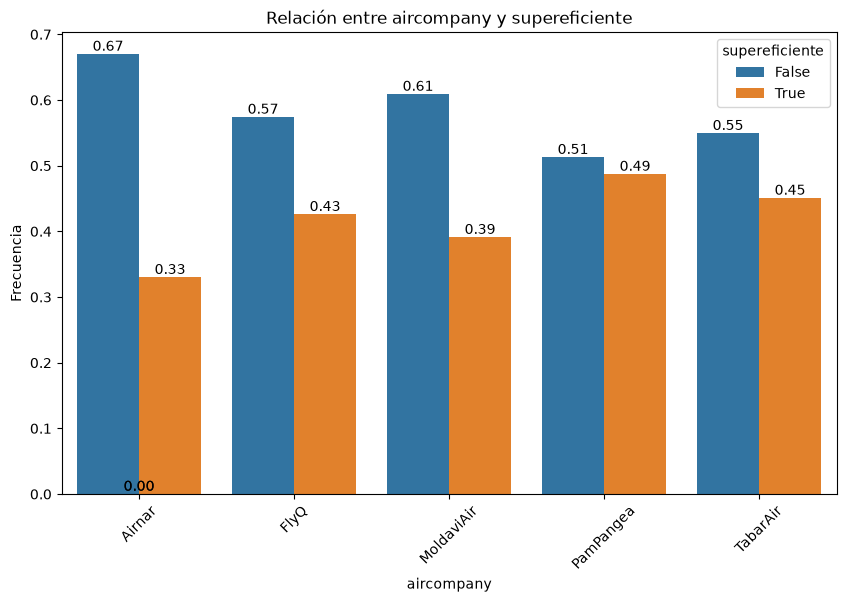

supereficiente  False  True 
aircompany                  
Airnar             67     33
FlyQ               62     46
MoldaviAir         81     52
PamPangea          60     57
TabarAir           78     64
p-valor: 0.1636762034569761


In [57]:
plot_categorical_relationship_fin(df_viajes, "aircompany", "supereficiente", relative_freq=True, show_values=True)
p = test_chi2(df_viajes, "aircompany", "supereficiente")

*Resultado: **no**. TabarAir tiene un 45 % de vuelos supereficientes, en la zona media-alta (el rango va del 33 % de Airnar al 49 % de PamPangea), y el chi-cuadrado **no permite afirmar que la eficiencia dependa de la compañía**. La eficiencia **no** explica la situación de TabarAir.*

Multivariantes con la compañía, la eficiencia y el avión, el destino o el origen.

In [58]:
# compañía - eficiencia - tipo de avión: ingreso mediano por km
df_viajes["ingreso_por_km"] = df_viajes["ingresos"] / df_viajes["distancia"]
df_viajes.pivot_table(index="aircompany", columns="avion", values="ingreso_por_km", aggfunc="median").round(1)

avion,Airbus A320,Airbus A380,Boeing 737,Boeing 747
aircompany,,,,
Airnar,39.6,63.8,35.2,59.4
FlyQ,39.8,63.1,36.2,58.7
MoldaviAir,39.6,62.7,35.2,59.2
PamPangea,39.1,62.4,35.7,59.8
TabarAir,39.2,63.2,35.4,59.3


*Con el **mismo avión**, todas las compañías ingresan lo mismo por km (39 en A320, 35 en B737, 63 en A380, 59 en B747). **TabarAir no cobra menos ni vuela peor**: su "precio por km" es idéntico al del resto. Entonces la diferencia puede estar en **cuántos km vuela en cada viaje**:*

In [59]:
df_viajes.groupby("aircompany").agg(distancia_mediana=("distancia", "median"),
                                    distancia_max=("distancia", "max"),
                                    ingreso_por_km=("ingreso_por_km", "median"),
                                    ingreso_mediano=("ingresos", "median")).sort_values("distancia_mediana").round(1)

,distancia_mediana,distancia_max,ingreso_por_km,ingreso_mediano
aircompany,,,,
TabarAir,6206.0,10077,57.1,258379.7
FlyQ,6877.0,16589,57.3,366970.7
Airnar,6969.0,15011,59.2,396764.2
PamPangea,11980.0,16925,56.9,442668.5
MoldaviAir,12553.0,20029,58.8,532426.2


In [60]:
(pd.crosstab(df_viajes["aircompany"], df_viajes["cat_vuelo"], normalize="index") * 100).round(1)

cat_vuelo,corto,medio,largo,muy_largo
aircompany,,,,
Airnar,31.0,37.0,25.0,7.0
FlyQ,22.2,46.3,22.2,9.3
MoldaviAir,25.6,14.3,24.8,35.3
PamPangea,28.2,19.7,16.2,35.9
TabarAir,38.0,62.0,0.0,0.0


In [61]:
# compañía - eficiencia - destino y origen
print("Viajes por compañía y DESTINO")
display(pd.crosstab(df_viajes["aircompany"], df_viajes["destino"]))
print("Viajes por compañía y ORIGEN")
display(pd.crosstab(df_viajes["aircompany"], df_viajes["origen"]))

Viajes por compañía y DESTINO


destino,Bali,Barcelona,Cincinnati,Cádiz,Ginebra,Londres,Los Angeles,Melbourne,Nueva York,París,Roma
aircompany,,,,,,,,,,,
Airnar,14,0,22,12,17,0,18,0,0,17,0
FlyQ,13,14,14,0,18,0,0,0,24,0,25
MoldaviAir,23,0,21,23,0,22,0,24,0,20,0
PamPangea,16,0,0,0,24,18,0,19,14,26,0
TabarAir,0,0,21,0,23,23,22,0,25,0,28


Viajes por compañía y ORIGEN


origen,Bali,Barcelona,Cincinnati,Cádiz,Ginebra,Londres,Los Angeles,Melbourne,Nueva York,París,Roma
aircompany,,,,,,,,,,,
Airnar,18,0,18,10,21,0,16,0,0,17,0
FlyQ,21,18,17,0,15,0,0,0,23,0,14
MoldaviAir,26,0,16,19,0,27,0,25,0,20,0
PamPangea,22,0,0,0,20,16,0,22,26,11,0
TabarAir,0,0,19,0,29,20,29,0,22,0,23


In [ ]:
# Las rutas más largas y quién vuela
df_viajes["ruta"] = df_viajes["origen"] + df_viajes["destino"]
largas = df_viajes[df_viajes["cat_vuelo"] == "muy_largo"]
pd.crosstab(largas["ruta"], largas["aircompany"]).assign(total=lambda x: x.sum(axis=1)).sort_values("total", ascending=False).head(10) # funcion lambda x:

aircompany,Airnar,FlyQ,MoldaviAir,PamPangea,total
ruta,,,,,
BaliCincinnati,6,1,6,0,13
MelbourneLondres,0,0,7,4,11
Nueva YorkBali,0,4,0,7,11
MelbourneParís,0,0,2,8,10
BaliNueva York,0,5,0,3,8
MelbourneCádiz,0,0,6,0,6
MelbourneCincinnati,0,0,6,0,6
CádizMelbourne,0,0,6,0,6
ParísMelbourne,0,0,4,2,6


In [63]:
# compañía - eficiencia - origen - destino 
tabar = df_viajes[df_viajes["aircompany"] == "TabarAir"]
(pd.crosstab([tabar["origen"], tabar["destino"]], tabar["supereficiente"], normalize="index") * 100).round(0).head(15)

supereficiente          False  True 
origen     destino                  
Cincinnati Ginebra      100.0    0.0
           Londres       50.0   50.0
           Los Angeles   60.0   40.0
           Nueva York    40.0   60.0
           Roma          40.0   60.0
Ginebra    Cincinnati    60.0   40.0
           Londres       83.0   17.0
           Los Angeles   67.0   33.0
           Nueva York    60.0   40.0
           Roma          29.0   71.0
Londres    Cincinnati   100.0    0.0
           Ginebra       43.0   57.0
           Los Angeles  100.0    0.0
           Nueva York    38.0   62.0
           Roma          67.0   33.0

### Respuesta -> TabarAir

1. **No es un problema de eficiencia.** La eficiencia depende solo del **tipo de avión** (A320/B737 supereficientes; A380/B747 no). TabarAir tiene una mezcla de flota similar a la del resto (45 % de vuelos supereficientes) y el chi-cuadrado no encuentra diferencias significativas entre compañías.
2. **Tampoco es un problema de precio.** Con el mismo avión, TabarAir ingresa **exactamente lo mismo por km** que sus competidores.
3. **Es un problema de red de rutas.** TabarAir **no vuela a Bali ni a Melbourne** (ni desde allí), y **todas** las rutas de más de 10.500 km (categorías largo y muy largo) tienen origen o destino en esas dos ciudades. Su vuelo más largo es de **10.000 km**, cuando el resto llega a 15.000-20.000 km. El **0 %** de sus viajes es largo o muy largo, frente al 31-60 % de las demás compañías. Su distancia mediana (**6.206 km**) es la más baja, y como en este negocio parece que **el ingreso es proporcional a la distancia** (r = 0,93), hace muchos viajes, pero "cortos" y de menor ingreso unitario.

